In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.linear_model import LinearRegression
import lightgbm as lgbm


In [2]:
train_data = pd.read_csv('../data/raw/train.csv')
print(train_data.head()) 
print(train_data.shape) 
print(train_data.info())

   id        date  store_nbr      family  sales  onpromotion
0   0  2013-01-01          1  AUTOMOTIVE    0.0            0
1   1  2013-01-01          1   BABY CARE    0.0            0
2   2  2013-01-01          1      BEAUTY    0.0            0
3   3  2013-01-01          1   BEVERAGES    0.0            0
4   4  2013-01-01          1       BOOKS    0.0            0
(3000888, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 6 columns):
 #   Column       Dtype  
---  ------       -----  
 0   id           int64  
 1   date         object 
 2   store_nbr    int64  
 3   family       object 
 4   sales        float64
 5   onpromotion  int64  
dtypes: float64(1), int64(3), object(2)
memory usage: 137.4+ MB
None


In [3]:
train_data.isna().mean().sort_values(ascending=False)

id             0.0
date           0.0
store_nbr      0.0
family         0.0
sales          0.0
onpromotion    0.0
dtype: float64

In [4]:
print(f"Daty od: {train_data['date'].min()} do: {train_data['date'].max()}")
print(f"Unikalnych sklepów: {train_data['store_nbr'].nunique()}")
print(f"Unikalnych rodzin produktów: {train_data['family'].nunique()}")
x = train_data[['date', 'store_nbr', 'family']].drop_duplicates().shape[0]
print(f"Uniklanych wartości date + store_nbr + family: {x} overall wierszy: {train_data.shape[0]}")
print(train_data['sales'].describe())
zero_sales_rows = (train_data['sales'] == 0)
zero_sales_data = train_data[zero_sales_rows]
print(f"Liczba wierszy z zerową sprzedażą: {zero_sales_data.shape[0]} Odsetek: {round(zero_sales_data.shape[0] / train_data.shape[0], 3)}")


Daty od: 2013-01-01 do: 2017-08-15
Unikalnych sklepów: 54
Unikalnych rodzin produktów: 33
Uniklanych wartości date + store_nbr + family: 3000888 overall wierszy: 3000888
count    3.000888e+06
mean     3.577757e+02
std      1.101998e+03
min      0.000000e+00
25%      0.000000e+00
50%      1.100000e+01
75%      1.958473e+02
max      1.247170e+05
Name: sales, dtype: float64
Liczba wierszy z zerową sprzedażą: 939130 Odsetek: 0.313


In [5]:
print(f"Uniklanych dni: {train_data['date'].nunique()}") 
x, y = train_data.groupby('date')['store_nbr'].size().min(), train_data.groupby('date')['store_nbr'].size().max()
print(x, y)
print(train_data['date'].dtype)


Uniklanych dni: 1684
1782 1782
object


In [6]:
train_data['date'] = pd.to_datetime(train_data['date'])
print(f"Typ: {train_data['date'].dtype}")
print(len(train_data['date']) - len(train_data['date'].drop_duplicates()))

Typ: datetime64[ns]
2999204


In [7]:
x = pd.date_range(train_data['date'].min(), train_data['date'].max())
print(len(x)) 


1688


In [8]:
unique_dates = train_data['date'].unique() 
print(x.difference(unique_dates))

DatetimeIndex(['2013-12-25', '2014-12-25', '2015-12-25', '2016-12-25'], dtype='datetime64[ns]', freq=None)


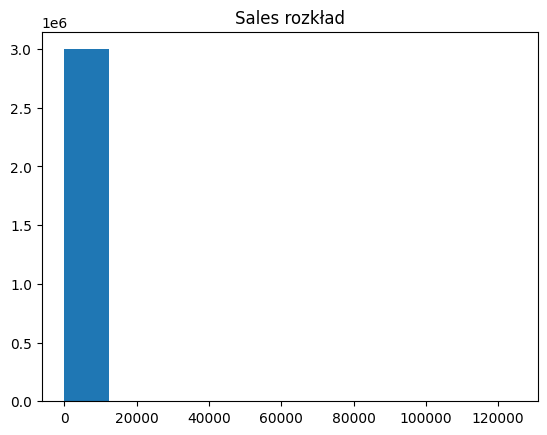

In [9]:
plt.hist(train_data['sales'])
plt.title('Sales rozkład')
plt.show()

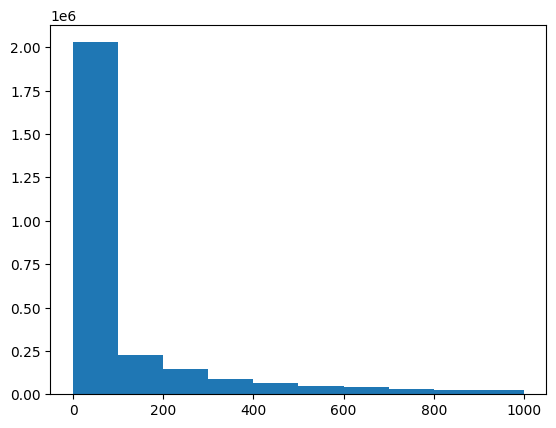

In [10]:
sales_under_1000 = train_data[train_data['sales'] <= 1000]
plt.hist(sales_under_1000['sales'])
plt.show()

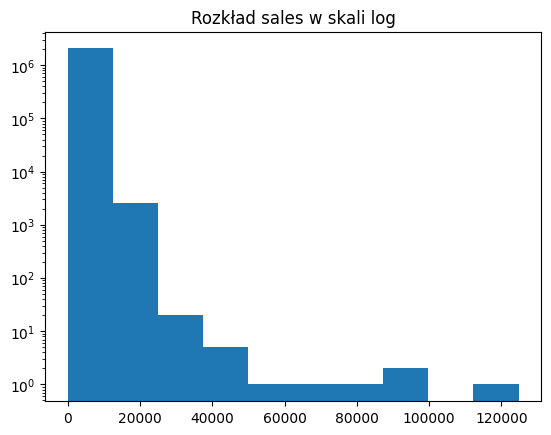

In [11]:
sales_without_zero = train_data[train_data['sales'] != 0]
plt.hist(sales_without_zero['sales'], log=True) 
plt.title('Rozkład sales w skali log')
plt.show()

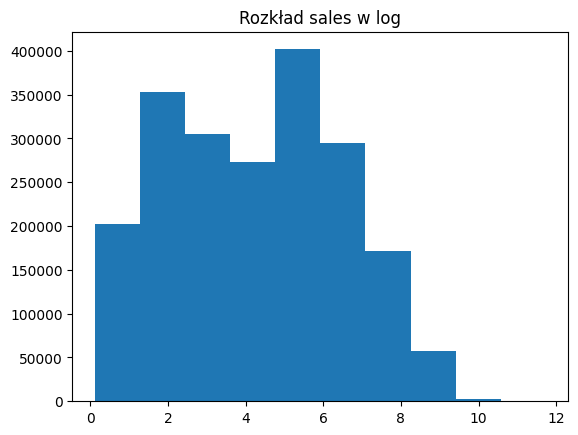

In [12]:
sales_log = np.log1p(sales_without_zero['sales'])
plt.hist(sales_log)
plt.title('Rozkład sales w log')
plt.show()

In [13]:
x = train_data.groupby('date')['sales'].sum().reset_index() 
x

,date,sales
0,2013-01-01,2511.618999
1,2013-01-02,496092.417944
2,2013-01-03,361461.231124
3,2013-01-04,354459.677093
4,2013-01-05,477350.121229
...,...,...
1679,2017-08-11,826373.722022
1680,2017-08-12,792630.535079
1681,2017-08-13,865639.677471
1682,2017-08-14,760922.406081


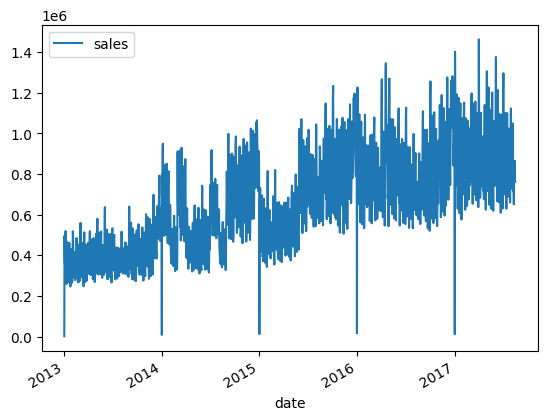

In [14]:
x.plot(x='date', y='sales', kind='line')
plt.show()

In [15]:
x = train_data.groupby('family')['sales'].sum().reset_index() 
x = x.sort_values(by='sales', ascending=False)
x

,family,sales
12,GROCERY I,3.434627e+08
3,BEVERAGES,2.169545e+08
30,PRODUCE,1.227047e+08
7,CLEANING,9.752129e+07
8,DAIRY,6.448771e+07
5,BREAD/BAKERY,4.213395e+07
28,POULTRY,3.187600e+07
24,MEATS,3.108647e+07
25,PERSONAL CARE,2.459205e+07
9,DELI,2.411032e+07


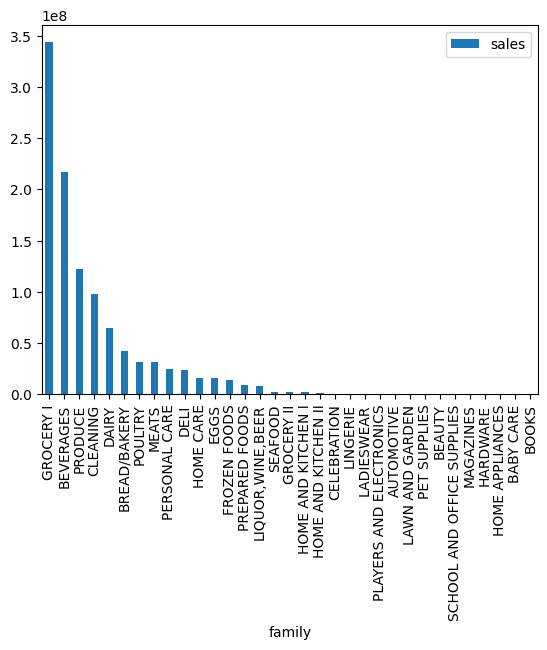

In [16]:
x.plot(x='family', y='sales', kind='bar')
plt.show()

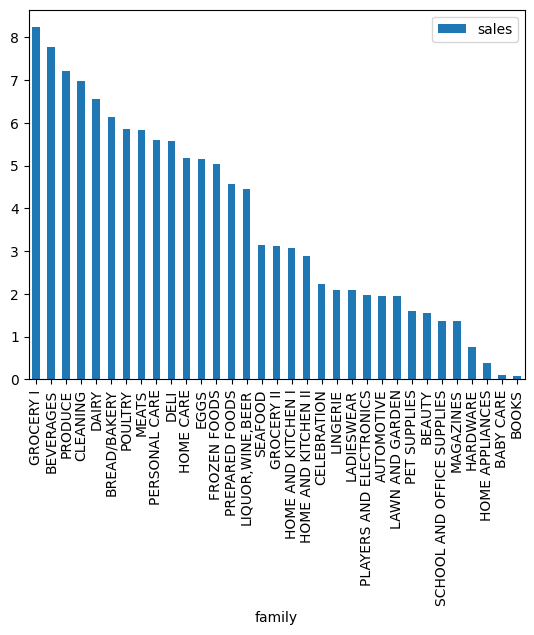

In [17]:
x = train_data.groupby('family')['sales'].mean().reset_index() 
x['sales'] = np.log1p(x['sales'])
x = x.sort_values(by='sales', ascending=False) 
x.plot(x='family', y='sales', kind='bar')
plt.show()

In [18]:
x = train_data.groupby('date')['sales'].sum().reset_index() 
x['day_of_week'] = x['date'].dt.dayofweek + 1
x = x.groupby('day_of_week')['sales'].mean().reset_index()
x

,day_of_week,sales
0,1,617542.713052
1,2,569926.087922
2,3,593244.553472
3,4,505269.201115
4,5,579574.361085
5,6,772205.593943
6,7,825218.121579


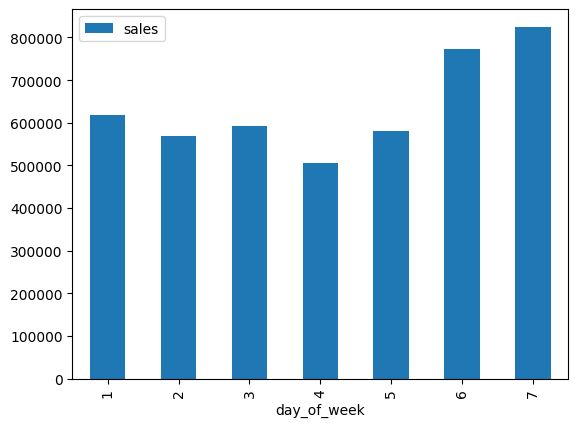

In [19]:
x.plot(x='day_of_week', y='sales', kind='bar')
plt.show()

In [20]:
x = train_data.groupby(['date', 'store_nbr'])['sales'].sum().reset_index() 
x['day_of_week'] = x['date'].dt.dayofweek + 1
x = x.groupby(['store_nbr', 'day_of_week'])['sales'].mean().reset_index() 
x

,store_nbr,day_of_week,sales
0,1,1,8811.158141
1,1,2,8620.853054
2,1,3,10807.164095
3,1,4,8246.262838
4,1,5,9507.712929
...,...,...,...
373,54,3,5175.736579
374,54,4,4891.553807
375,54,5,5538.062629
376,54,6,7412.684369


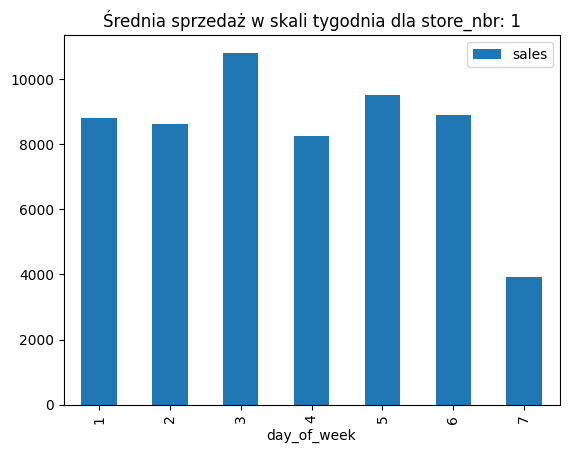

In [21]:
x = x[x['store_nbr'] == 1] 
x.plot(x='day_of_week', y='sales', kind='bar')
plt.title('Średnia sprzedaż w skali tygodnia dla store_nbr: 1')
plt.show()

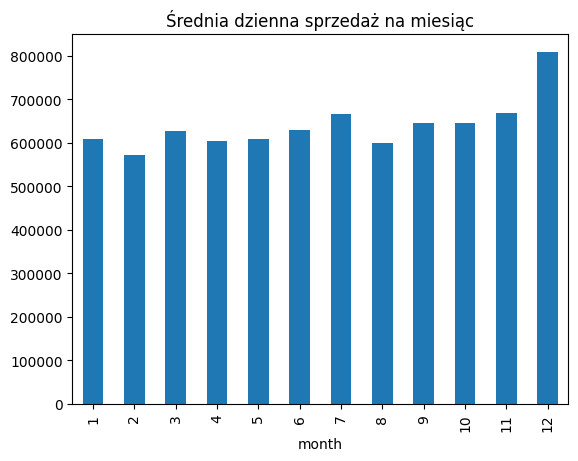

In [22]:
x = train_data.groupby('date')['sales'].sum().reset_index() 
x['month'] = x['date'].dt.month 
x = x.groupby('month')['sales'].mean() 
x.plot(x='month', y='sales', kind='bar')
plt.title('Średnia dzienna sprzedaż na miesiąc')
plt.show()

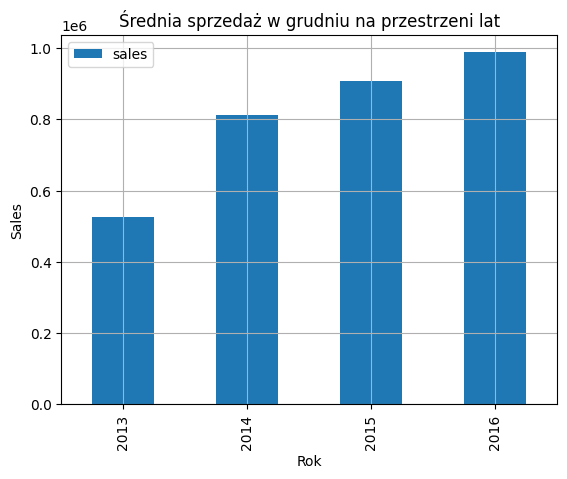

In [23]:
x = train_data.groupby('date')['sales'].sum().reset_index() 
x['year'] = x['date'].dt.year
x['month'] = x['date'].dt.month 
x = x.groupby(['year', 'month'])['sales'].mean().reset_index() 
x = x[x['month'] == 12]
x.plot(x='year', y='sales', kind='bar')
plt.title('Średnia sprzedaż w grudniu na przestrzeni lat')
plt.xlabel('Rok')
plt.ylabel('Sales')
plt.grid(True)
plt.show() 

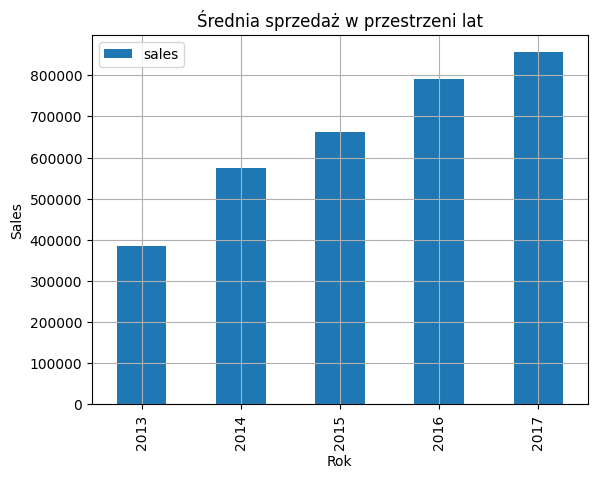

In [24]:
x = train_data.groupby('date')['sales'].sum().reset_index() 
x['year'] = x['date'].dt.year 
x = x.groupby('year')['sales'].mean().reset_index() 
x.plot(x='year', y='sales', kind='bar')
plt.title('Średnia sprzedaż w przestrzeni lat')
plt.xlabel('Rok')
plt.ylabel('Sales')
plt.grid(True)
plt.show() 

In [25]:
X = train_data.copy() 
X = X.groupby('date')['sales'].sum().reset_index() 
X = X.sort_values(by='date', ascending=True)
X['prediction'] = X['sales'].shift(1)
X_train = X[X['date'] <= pd.to_datetime('2016-12-31')]
X_test = X[X['date'] >= pd.to_datetime('2017-01-01')]
print(X_train.shape, X_train['date'].min(), X_train['date'].max())
print(X_test.shape, X_test['date'].min(), X_test['date'].max()) 

mae = mean_absolute_error(X_test['sales'], X_test['prediction'])
print(f" Simple baseline Mean absolute error: {mae:.4f}")

(1457, 3) 2013-01-01 00:00:00 2016-12-31 00:00:00
(227, 3) 2017-01-01 00:00:00 2017-08-15 00:00:00
 Simple baseline Mean absolute error: 162293.7186


In [26]:
mean_test_sales = X_test['sales'].mean()
mae_pct = mae / mean_test_sales 
print(mae_pct)

0.1896881382561326


In [27]:
X = X.sort_values(by='date', ascending=True)
X['prev_year_sales'] = X['sales'].shift(364) 
X = X.sort_values(by='date', ascending=True)
X_train = X[X['date'] <= pd.to_datetime('2016-12-31')]
X_test = X[X['date'] >= pd.to_datetime('2017-01-01')]
mae2 = mean_absolute_error(X_test['sales'], X_test['prev_year_sales'])
print(f"Baseline prosty v2 MAE: {mae2:.4f}")

Baseline prosty v2 MAE: 172286.5207


In [28]:
train_data.head()

,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


In [29]:
X_copy = train_data.copy()
X_copy = X_copy.groupby('date')['sales'].sum().reset_index() 
lag_df = X_copy[['date', 'sales']].copy()
lag_df['date'] = lag_df['date']  + pd.Timedelta(days=364)
lag_df = lag_df.rename(columns={'sales':'prev_year_sales'})
X_full = pd.merge(X_copy, lag_df, on='date', how='left')

X_full = X_full.sort_values(by='date', ascending=True)
X_train = X_full[X_full['date'] <= pd.to_datetime('2016-12-31')]
X_test = X_full[X_full['date'] >= pd.to_datetime('2017-01-01')]

mae3 = mean_absolute_error(X_test['sales'], X_test['prev_year_sales'])
print(f"Mae baseline prev_year_sales: {mae3:.4f}")


Mae baseline prev_year_sales: 121617.8573


In [30]:
X_full['t'] = (X_full['date'] - X_full['date'].min()).dt.days 
X_train = X_full[X_full['date'] <= pd.to_datetime('2016-12-31')]
X_test = X_full[X_full['date'] >= pd.to_datetime('2017-01-01')]

lr = LinearRegression() 
lr.fit(X_train[['t']], X_train['sales'])
trend_pred = lr.predict(X_test[['t']])
trend_prev_year = lr.predict((X_test[['t']] - 364))

X_test['corrected_pred'] = X_test['prev_year_sales'] + trend_pred - trend_prev_year 
X_test = X_test.dropna()
mae = mean_absolute_error(X_test['sales'], X_test['corrected_pred'])
print(f"Corrected baseline by LR MAE: {mae:.4f}")

Corrected baseline by LR MAE: 83461.0613


C:\Users\szymo\AppData\Local\Temp\ipykernel_27216\1261376444.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X_test['corrected_pred'] = X_test['prev_year_sales'] + trend_pred - trend_prev_year


In [31]:
print(train_data.head()) 
print(train_data.shape)
print(train_data.dtypes)

   id       date  store_nbr      family  sales  onpromotion
0   0 2013-01-01          1  AUTOMOTIVE    0.0            0
1   1 2013-01-01          1   BABY CARE    0.0            0
2   2 2013-01-01          1      BEAUTY    0.0            0
3   3 2013-01-01          1   BEVERAGES    0.0            0
4   4 2013-01-01          1       BOOKS    0.0            0
(3000888, 6)
id                      int64
date           datetime64[ns]
store_nbr               int64
family                 object
sales                 float64
onpromotion             int64
dtype: object


In [32]:
for col in train_data.columns: 
    print(f"{col} : {train_data[col].nunique()}")

id : 3000888
date : 1684
store_nbr : 54
family : 33
sales : 379610
onpromotion : 362


In [33]:
train_data.duplicated(subset=['date', 'store_nbr', 'family']).sum()

np.int64(0)

In [34]:
train_data.groupby(['date','store_nbr', 'family']).size().describe()

count    3000888.0
mean           1.0
std            0.0
min            1.0
25%            1.0
50%            1.0
75%            1.0
max            1.0
dtype: float64

In [35]:
train_data.groupby(['store_nbr', 'family']).size().value_counts()

1684    1782
Name: count, dtype: int64

In [36]:
train_data[['date', 'store_nbr', 'family']].drop_duplicates().shape

(3000888, 3)

In [37]:
train_data.groupby(['store_nbr', 'family']).size().sum()

np.int64(3000888)

In [38]:
train_data['date'].value_counts().sort_values().value_counts()

count
1782    1684
Name: count, dtype: int64

In [39]:
def calendar_features(X : pd.DataFrame) -> pd.DataFrame: 
    X['year'] = X['date'].dt.year
    X['month'] = X['date'].dt.month
    X['day_of_week'] = X['date'].dt.dayofweek + 1
    X['day_of_month'] = X['date'].dt.day
    X['is_weekend'] = np.where((X['day_of_week'] == 6) | (X['day_of_week'] == 7), 1, 0)
    return X

In [40]:
def add_lag_features(X : pd.DataFrame) -> pd.DataFrame:
    X['lag_7'] = X.groupby(['store_nbr', 'family'])['sales'].shift(7)
    X['lag_14'] = X.groupby(['store_nbr', 'family'])['sales'].shift(14)
    X['lag_28'] = X.groupby(['store_nbr', 'family'])['sales'].shift(28)
    X['lag_364'] = X.groupby(['store_nbr', 'family'])['sales'].shift(364)
    return X

In [41]:
def add_rolling_features(X : pd.DataFrame) -> pd.DataFrame: 
    X['rolling_mean_7'] = X.groupby(['store_nbr', 'family'])['sales'].transform(lambda x: x.shift(1).rolling(7).mean())
    X['rolling_mean_28'] = X.groupby(['store_nbr', 'family'])['sales'].transform(lambda x: x.shift(1).rolling(28).mean())
    X['rolling_std_7'] = X.groupby(['store_nbr', 'family'])['sales'].transform(lambda x: x.shift(1).rolling(7).std()) 
    return X 

In [42]:
def sort_data(X: pd.DataFrame) -> pd.DataFrame: 
    return X.sort_values(by=['store_nbr', 'family', 'date']).copy()

def preprocessor(X : pd.DataFrame) -> pd.DataFrame: 
    X_sorted = sort_data(X)
    return add_rolling_features(add_lag_features(calendar_features(X_sorted)))

X_after_all = preprocessor(train_data) 
X_after_all.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3000888 entries, 0 to 3000755
Data columns (total 18 columns):
 #   Column           Dtype         
---  ------           -----         
 0   id               int64         
 1   date             datetime64[ns]
 2   store_nbr        int64         
 3   family           object        
 4   sales            float64       
 5   onpromotion      int64         
 6   year             int32         
 7   month            int32         
 8   day_of_week      int32         
 9   day_of_month     int32         
 10  is_weekend       int64         
 11  lag_7            float64       
 12  lag_14           float64       
 13  lag_28           float64       
 14  lag_364          float64       
 15  rolling_mean_7   float64       
 16  rolling_mean_28  float64       
 17  rolling_std_7    float64       
dtypes: datetime64[ns](1), float64(8), int32(4), int64(4), object(1)
memory usage: 389.2+ MB


In [43]:
print(f"Shape: {X_after_all.shape}")
print(X_after_all.isna().mean().sort_values(ascending=False))
print(X_after_all.dtypes)
print(X_after_all.head())

Shape: (3000888, 18)
lag_364            0.216152
lag_28             0.016627
rolling_mean_28    0.016627
lag_14             0.008314
lag_7              0.004157
rolling_std_7      0.004157
rolling_mean_7     0.004157
id                 0.000000
date               0.000000
store_nbr          0.000000
day_of_month       0.000000
day_of_week        0.000000
month              0.000000
year               0.000000
onpromotion        0.000000
sales              0.000000
family             0.000000
is_weekend         0.000000
dtype: float64
id                          int64
date               datetime64[ns]
store_nbr                   int64
family                     object
sales                     float64
onpromotion                 int64
year                        int32
month                       int32
day_of_week                 int32
day_of_month                int32
is_weekend                  int64
lag_7                     float64
lag_14                    float64
lag_28            

In [44]:

def prepare_and_split_data(df : pd.DataFrame): 
    x = preprocessor(df) 
    x['family'] = x['family'].astype('category')
    train = x[x['date'] <= '2016-12-31']
    val = x[x['date'] >= '2017-01-01']
    y_train = train['sales'].copy() 
    y_val = val['sales'].copy() 
    X_train = train.drop(columns=['id', 'date', 'sales'])
    X_val = val.drop(columns=['id', 'date', 'sales'])
    return X_train, X_val, y_train, y_val


X_train, X_val, y_train, y_val = prepare_and_split_data(train_data)
print(X_train.shape, X_val.shape, y_train.shape, y_val.shape)

(2596374, 15) (404514, 15) (2596374,) (404514,)


In [45]:
lgb = lgbm.LGBMRegressor(objective='regression', n_estimators=500, learning_rate=0.05, 
                         num_leaves=31, max_depth=-1, random_state=42, n_jobs=-1)
lgb.fit(X_train, y_train) 
y_pred = lgb.predict(X_val) 

mae = mean_absolute_error(y_val, y_pred) 
rmse = root_mean_squared_error(y_val, y_pred) 

print(f"MAE: {mae}")
print(f"RMSE: {rmse}")

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.089614 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2129
[LightGBM] [Info] Number of data points in the train set: 2596374, number of used features: 15
[LightGBM] [Info] Start training from score 338.713869
MAE: 73.8983149410207
RMSE: 321.18710170754036


In [46]:
residual = y_val - y_pred

print(residual.mean())
print(residual.median())
print(residual.std()) 
print(residual.min(), residual.max())


-3.2139356634440994
0.11750981873752082
321.1714182813683
-18238.594776331756 22611.69811816499


C:\Users\szymo\AppData\Local\Temp\ipykernel_27216\2265374448.py:4: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


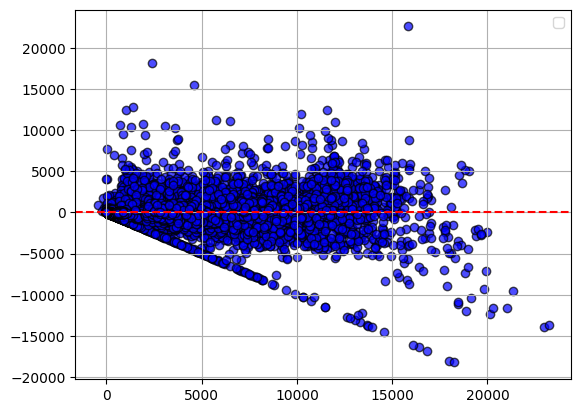

In [47]:
plt.scatter(y_pred, residual, color='blue', edgecolor='k', alpha=0.7)
plt.axhline(y=0, color='red', linestyle='--', linewidth=1.5)
plt.grid(True) 
plt.legend() 
plt.show()

In [48]:
mask = (y_pred >= 0) & (y_pred < 5000) 
res_interval = residual[mask]
print("Mean:", np.mean(res_interval))
print("Median:", np.median(res_interval))
print("Std:", np.std(res_interval))
print("Count:", len(res_interval))

Mean: -4.4706754550223815
Median: -0.5515293747687835
Std: 201.73041597691855
Count: 356865


In [49]:
mask = (y_pred >= 5000) & (y_pred < 10000) 
res_interval = residual[mask]
print("Mean:", np.mean(res_interval))
print("Median:", np.median(res_interval))
print("Std:", np.std(res_interval))
print("Count:", len(res_interval))

Mean: -14.455090023139471
Median: -17.89268303969766
Std: 1376.2655339716723
Count: 6263


In [50]:
mask = (y_pred >= 10000) & (y_pred < 20000) 
res_interval = residual[mask]
print("Mean:", np.mean(res_interval))
print("Median:", np.median(res_interval))
print("Std:", np.std(res_interval))
print("Count:", len(res_interval))

Mean: 291.4939064367219
Median: 414.45880021897574
Std: 3341.146475935272
Count: 1282


In [51]:
mask = (y_pred >= 20000) & (y_pred < 25000) 
res_interval = residual[mask]
print("Mean:", np.mean(res_interval))
print("Median:", np.median(res_interval))
print("Std:", np.std(res_interval))
print("Count:", len(res_interval))

Mean: -12121.877991417487
Median: -11980.814841544085
Std: 1456.7951163682371
Count: 6


In [52]:
X_val['pred'], X_val['true']= y_pred, y_val
more_than_25 = X_val[X_val['pred'] >= 20000]
print(more_than_25)
print(more_than_25.shape)

         store_nbr     family  onpromotion  year  month  day_of_week  \
2788314         44  GROCERY I           89  2017      4            2   
2790096         44  GROCERY I          122  2017      4            3   
2788347         45  GROCERY I          109  2017      4            2   
2790129         45  GROCERY I          133  2017      4            3   
2791911         45  GROCERY I          106  2017      4            4   
2793693         45  GROCERY I          112  2017      4            5   

         day_of_month  is_weekend    lag_7   lag_14   lag_28  lag_364  \
2788314            18           0   7791.0   7337.0   8945.0  29193.0   
2790096            19           0   8690.0   8358.0   9165.0  24861.0   
2788347            18           0   9337.0  13095.0   8893.0  76090.0   
2790129            19           0   9471.0  12071.0  10114.0  15282.0   
2791911            20           0   9112.0   8631.0   8445.0  14726.0   
2793693            21           0  10333.0  11675.0  1124

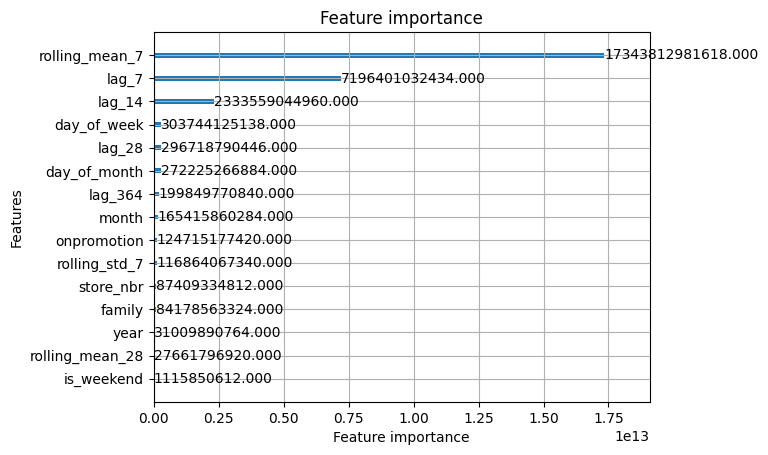

In [53]:
lgbm.plot_importance(lgb, importance_type="gain")

plt.show()

In [54]:
stores_df = pd.read_csv('../data/raw/stores.csv')
print(stores_df.head())
print(stores_df.shape)

   store_nbr           city                           state type  cluster
0          1          Quito                       Pichincha    D       13
1          2          Quito                       Pichincha    D       13
2          3          Quito                       Pichincha    D        8
3          4          Quito                       Pichincha    D        9
4          5  Santo Domingo  Santo Domingo de los Tsachilas    D        4
(54, 5)


In [55]:
import sys 
sys.path.append('../src')
from preprocessing import prepare_and_split_data

In [56]:
X_train, X_val, y_train, y_val = prepare_and_split_data(
    train_data, 
    additional_files=['stores.csv'], 
    merge_keys=['store_nbr']
)

In [57]:
print(X_train.isna().mean().sort_values(ascending=False))
print('________________________')
print(X_val.isna().mean().sort_values(ascending=False))

lag_364            0.249828
lag_28             0.019218
rolling_mean_28    0.019218
lag_14             0.009609
rolling_std_7      0.004804
lag_7              0.004804
rolling_mean_7     0.004804
onpromotion        0.000000
family             0.000000
store_nbr          0.000000
year               0.000000
is_weekend         0.000000
month              0.000000
day_of_week        0.000000
day_of_month       0.000000
city               0.000000
state              0.000000
type               0.000000
cluster            0.000000
dtype: float64
________________________
store_nbr          0.0
family             0.0
onpromotion        0.0
year               0.0
month              0.0
day_of_week        0.0
day_of_month       0.0
is_weekend         0.0
lag_7              0.0
lag_14             0.0
lag_28             0.0
lag_364            0.0
rolling_mean_7     0.0
rolling_mean_28    0.0
rolling_std_7      0.0
city               0.0
state              0.0
type               0.0
cluster       

In [58]:
lgb = lgbm.LGBMRegressor(objective='regression', n_estimators=500, learning_rate=0.05, 
                         num_leaves=31, max_depth=-1, random_state=42, n_jobs=-1)
lgb.fit(X_train, y_train) 
y_pred = lgb.predict(X_val) 

mae = mean_absolute_error(y_val, y_pred) 
rmse = root_mean_squared_error(y_val, y_pred) 

print(f"MAE po dołączeniu stores.csv: {mae}")
print(f"RMSE po dołączeniu stores.csv: {rmse}")

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.070858 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2193
[LightGBM] [Info] Number of data points in the train set: 2596374, number of used features: 19
[LightGBM] [Info] Start training from score 338.713869
MAE po dołączeniu stores.csv: 73.06949913388625
RMSE po dołączeniu stores.csv: 317.8968357378999


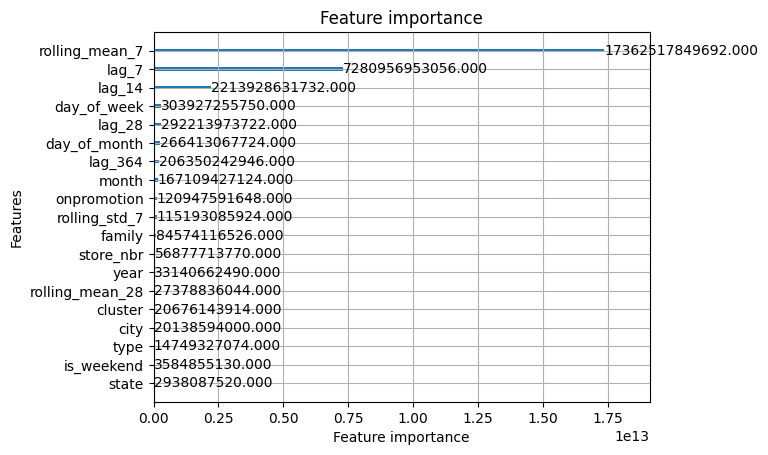

In [59]:
lgbm.plot_importance(lgb, importance_type="gain")
plt.show()

In [62]:
from preprocessing import load_additional_data
files = ['stores', 'oil', 'holidays_events', 'transactions']

for file in files: 
    df = load_additional_data(file+'.csv')
    print(f'\n{"=" * 50}')
    print(file)
    print('Shape:', df.shape)
    print('Columns:', df.columns.tolist())
    print('Dtypes:')
    print(df.dtypes)
    print('Duplicates:', df.duplicated().sum())
    print('Missing values:')
    print(df.isna().sum())
    print(df.head(3).to_string(index=False))


stores
Shape: (54, 5)
Columns: ['store_nbr', 'city', 'state', 'type', 'cluster']
Dtypes:
store_nbr     int64
city         object
state        object
type         object
cluster       int64
dtype: object
Duplicates: 0
Missing values:
store_nbr    0
city         0
state        0
type         0
cluster      0
dtype: int64
 store_nbr  city     state type  cluster
         1 Quito Pichincha    D       13
         2 Quito Pichincha    D       13
         3 Quito Pichincha    D        8

oil
Shape: (1218, 2)
Columns: ['date', 'dcoilwtico']
Dtypes:
date           object
dcoilwtico    float64
dtype: object
Duplicates: 0
Missing values:
date           0
dcoilwtico    43
dtype: int64
      date  dcoilwtico
2013-01-01         NaN
2013-01-02       93.14
2013-01-03       92.97

holidays_events
Shape: (350, 6)
Columns: ['date', 'type', 'locale', 'locale_name', 'description', 'transferred']
Dtypes:
date           object
type           object
locale         object
locale_name    object
description    

In [63]:
transactions = load_additional_data('transactions.csv')
holidays = load_additional_data('holidays_events.csv')

print('TRANSACTIONS')
print('Date range:', transactions['date'].min(), transactions['date'].max())
print('Unique stores:', transactions['store_nbr'].nunique())
print('Unique store-date:', transactions[['store_nbr', 'date']].drop_duplicates().shape[0])

print('\nHOLIDAYS')
print('Date range:', holidays['date'].min(), holidays['date'].max())
print('Unique dates:', holidays['date'].nunique())

print('\nEvents per date:')
print(holidays.groupby('date').size().value_counts().sort_index())

print('\nLocale distribution:')
print(holidays['locale'].value_counts())

print('\nEvent types:')
print(holidays['type'].value_counts())

TRANSACTIONS
Date range: 2013-01-01 2017-08-15
Unique stores: 54
Unique store-date: 83488

HOLIDAYS
Date range: 2012-03-02 2017-12-26
Unique dates: 312

Events per date:
1    281
2     25
3      5
4      1
Name: count, dtype: int64

Locale distribution:
locale
National    174
Local       152
Regional     24
Name: count, dtype: int64

Event types:
type
Holiday       221
Event          56
Additional     51
Transfer       12
Bridge          5
Work Day        5
Name: count, dtype: int64


In [ ]:
holidays = load_additional_data('holidays_events.csv')